<a href="https://colab.research.google.com/github/Mahyarnaeimi/Focus/blob/main/Assignment3_fixed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercise: Predicting Chemotherapy Resistance from DNA Methylation Data

**Goal:** predict whether a sample is chemotherapy-**resistant** (1) or **sensitive** (0) from DNA methylation beta values measured at 10 CpG sites.

**Workflow**
1. Data generation, loading and exploration
2. Stratified 5-fold cross-validation: Random Forest vs. SVC (accuracy)
3. Evaluation and testing: ROC-AUC, ROC curves, hold-out test, feature importance
4. Class-imbalance handling: SMOTE, Random Over-Sampling, class weights

In [ ]:
# imbalanced-learn provides SMOTE and RandomOverSampler (Step 4). No-op if it is already installed.
%pip install -q imbalanced-learn

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_validate, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

print("Environment initialized and libraries loaded successfully!")

Environment initialized and libraries loaded successfully!


## Data Generation (helper code)

Run the next cell to create the synthetic dataset. If you already have `methylation.csv` and `Chemoresistance_labels.csv`, skip it.

In [2]:
# Helper code to generate synthetic DNA methylation data for the exercise
np.random.seed(42)  # reproducibility

n_samples = 200
n_cpg_sites = 10

# Methylation beta values (0.0 - 1.0): proportion of methylated molecules at each CpG site
methylation_data = np.random.beta(a=2, b=5, size=(n_samples, n_cpg_sites))
cpg_columns = [f"CpG_site_{i+1}" for i in range(n_cpg_sites)]
methylation_df_synthetic = pd.DataFrame(methylation_data, columns=cpg_columns)

# Target labels (0 = Sensitive, 1 = Resistant). The label depends (linearly, plus noise)
# on CpG_site_1 (higher -> more resistant) and CpG_site_2 (higher -> more sensitive).
linear_combination = (3.0 * methylation_df_synthetic["CpG_site_1"]
                      - 4.5 * methylation_df_synthetic["CpG_site_2"]
                      + np.random.normal(0, 0.5, n_samples))
probability = 1 / (1 + np.exp(-linear_combination))
labels = (probability > 0.5).astype(int)
labels_df_synthetic = pd.DataFrame({"Chemoresistance": labels})

# Save to CSV so the pipeline below can load them
methylation_df_synthetic.to_csv('methylation.csv', index=False)
labels_df_synthetic.to_csv('Chemoresistance_labels.csv', index=False)
print("Synthetic datasets ('methylation.csv' and 'Chemoresistance_labels.csv') saved to the workspace.")

Synthetic datasets ('methylation.csv' and 'Chemoresistance_labels.csv') saved to the workspace.


## Step 1: Data Loading and Exploration

In [3]:
# Fail early with a clear message instead of continuing with undefined variables
for f in ['methylation.csv', 'Chemoresistance_labels.csv']:
    if not Path(f).exists():
        raise FileNotFoundError(f"'{f}' not found. Run the data-generation cell above or upload the file to the workspace.")

methylation_df = pd.read_csv('methylation.csv')
labels_df = pd.read_csv('Chemoresistance_labels.csv')
print(f"Methylation shape: {methylation_df.shape}")
print(f"Labels shape:      {labels_df.shape}")

# Combine features and labels into a single table
if 'Cell ID' in methylation_df.columns and 'Cell ID' in labels_df.columns:
    # Data with an ID column: match rows by ID (inner join -> no NaN labels for unmatched IDs)
    df = methylation_df.merge(labels_df, on='Cell ID', how='inner', validate='one_to_one').set_index('Cell ID')
    print("Combined using the 'Cell ID' column.")
else:
    # No ID column (synthetic data): rows are aligned by position
    assert len(methylation_df) == len(labels_df), "Methylation and label tables have different numbers of rows"
    df = pd.concat([methylation_df, labels_df], axis=1)
    print("No 'Cell ID' column found; combined by row position.")

X = df.drop(columns='Chemoresistance')  # features: methylation beta values
y = df['Chemoresistance']               # target: 0 = Sensitive, 1 = Resistant

Methylation shape: (200, 10)
Labels shape:      (200, 1)
No 'Cell ID' column found; combined by row position.


In [4]:
print("--- First rows ---")
display(df.head())

print("\n--- Column types and non-null counts ---")
df.info()

print("\n--- Summary statistics of the CpG sites ---")
display(X.describe().T)

print("\n--- Class distribution (Chemoresistance) ---")
class_counts = y.value_counts().sort_index()
display(pd.DataFrame({'count': class_counts, 'percent': (class_counts / len(y) * 100).round(1)}))
print(f"Imbalance ratio (majority : minority) = {class_counts.max() / class_counts.min():.2f} : 1")

print(f"\nMissing values in the combined dataset: {df.isnull().sum().sum()}")

--- First rows ---


,CpG_site_1,CpG_site_2,CpG_site_3,CpG_site_4,CpG_site_5,CpG_site_6,CpG_site_7,CpG_site_8,CpG_site_9,CpG_site_10,Chemoresistance
0,0.353677,0.248558,0.415959,0.159968,0.550283,0.110945,0.509897,0.177270,0.198290,0.376237,0
1,0.543467,0.084764,0.357929,0.273321,0.134376,0.353255,0.132790,0.326434,0.165810,0.207734,1
2,0.263408,0.390014,0.153645,0.305502,0.203314,0.183877,0.367824,0.202097,0.186340,0.283520,0
3,0.100399,0.207729,0.309638,0.044386,0.124579,0.211003,0.358189,0.652242,0.162266,0.069424,0
4,0.076848,0.174434,0.543454,0.061654,0.235687,0.313294,0.152583,0.386886,0.484590,0.095939,0



--- Column types and non-null counts ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CpG_site_1       200 non-null    float64
 1   CpG_site_2       200 non-null    float64
 2   CpG_site_3       200 non-null    float64
 3   CpG_site_4       200 non-null    float64
 4   CpG_site_5       200 non-null    float64
 5   CpG_site_6       200 non-null    float64
 6   CpG_site_7       200 non-null    float64
 7   CpG_site_8       200 non-null    float64
 8   CpG_site_9       200 non-null    float64
 9   CpG_site_10      200 non-null    float64
 10  Chemoresistance  200 non-null    int64  
dtypes: float64(10), int64(1)
memory usage: 17.3 KB

--- Summary statistics of the CpG sites ---


,count,mean,std,min,25%,50%,75%,max
CpG_site_1,200.0,0.292242,0.148130,0.013097,0.184176,0.278005,0.380524,0.718299
CpG_site_2,200.0,0.297315,0.166960,0.009064,0.167752,0.278030,0.413949,0.753457
CpG_site_3,200.0,0.301241,0.152644,0.038261,0.178071,0.279860,0.417187,0.681655
CpG_site_4,200.0,0.280702,0.152633,0.013338,0.158010,0.264297,0.386959,0.723903
CpG_site_5,200.0,0.282980,0.166617,0.007248,0.144198,0.274967,0.409970,0.813342
CpG_site_6,200.0,0.284095,0.153005,0.025530,0.163994,0.265240,0.372362,0.659463
CpG_site_7,200.0,0.296475,0.163824,0.007275,0.167281,0.272261,0.421321,0.741945
CpG_site_8,200.0,0.308528,0.164798,0.031426,0.186090,0.275409,0.417893,0.801473
CpG_site_9,200.0,0.280259,0.152185,0.026592,0.165497,0.251795,0.389713,0.747542
CpG_site_10,200.0,0.279064,0.168178,0.005368,0.150542,0.243365,0.376444,0.735224



--- Class distribution (Chemoresistance) ---


,count,percent
Chemoresistance,,
0,131,65.5
1,69,34.5


Imbalance ratio (majority : minority) = 1.90 : 1

Missing values in the combined dataset: 0


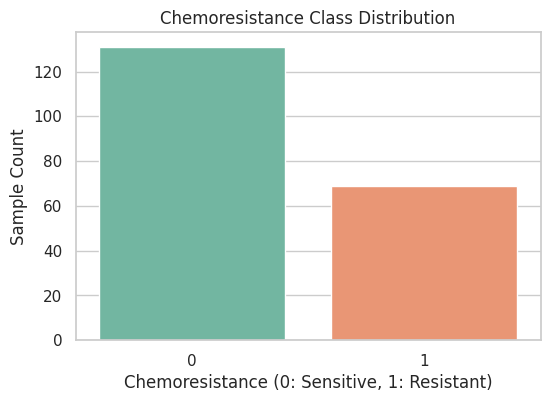

In [5]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Chemoresistance', hue='Chemoresistance', palette='Set2', legend=False)
plt.title('Chemoresistance Class Distribution')
plt.xlabel('Chemoresistance (0: Sensitive, 1: Resistant)')
plt.ylabel('Sample Count')
plt.show()

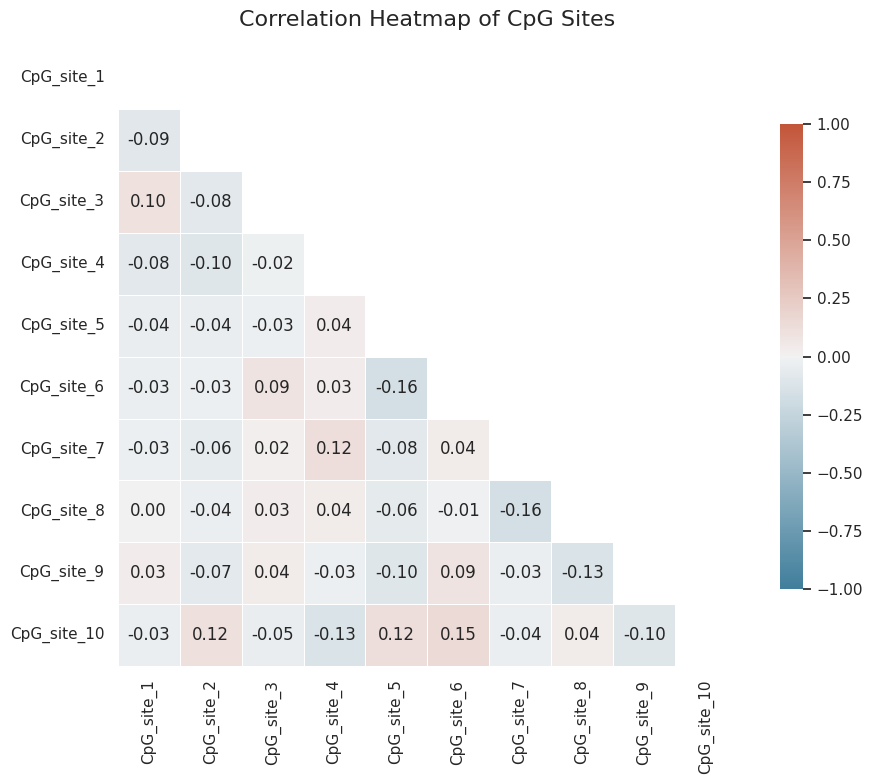

Largest absolute pairwise correlation between CpG sites: 0.16


In [6]:
# Correlation between CpG sites (lower triangle only; the upper triangle is a mirror image)
cpg_corr = X.corr()
mask = np.triu(np.ones_like(cpg_corr, dtype=bool))

plt.figure(figsize=(10, 8))
with sns.axes_style("white"):  # no grid lines behind the heatmap
    sns.heatmap(
        cpg_corr,
        mask=mask,
        annot=True,
        fmt=".2f",
        cmap=sns.diverging_palette(230, 20, as_cmap=True),
        vmin=-1, vmax=1, center=0,
        square=True,
        linewidths=.5,
        cbar_kws={"shrink": .75},
    )
plt.title('Correlation Heatmap of CpG Sites', fontsize=16, pad=15)
plt.tight_layout()
plt.show()

off_diagonal = cpg_corr.where(~np.eye(len(cpg_corr), dtype=bool))
print(f"Largest absolute pairwise correlation between CpG sites: {off_diagonal.abs().max().max():.2f}")

### Step 2: 5-Fold Cross Validation

We evaluate two models with **stratified 5-fold cross-validation** and compare them with a trivial majority-class baseline:
1. **Random Forest Classifier**
2. **Support Vector Classifier (SVC)** (RBF kernel)

**Technical decisions:**
* **Preventing data leakage:** `StandardScaler` is wrapped in a `Pipeline`, so it is fitted only on the training part of each fold.
* **Missing values:** none were found in Step 1, so imputation is not needed.
* **Stratification:** `StratifiedKFold` keeps the class proportions in every fold.
* **Baseline:** about 65% of the samples are "Sensitive", so a model that always predicts the majority class already reaches roughly 0.65 accuracy. A useful model has to beat this.

In [9]:
METHODS = ['Baseline', 'SMOTE', 'ROS', 'Class weight']   # used in Step 4


def build_pipeline(model_name, method='Baseline'):
    """Scaler -> (optional sampler) -> classifier.
    Samplers sit inside the pipeline, so they only ever see the training part of a CV fold."""
    if method not in METHODS:
        raise ValueError(f"Unknown method: {method}")
    class_weight = 'balanced' if method == 'Class weight' else None

    if model_name == 'Random Forest':
        clf = RandomForestClassifier(n_estimators=100, class_weight=class_weight, random_state=RANDOM_STATE)
    elif model_name == 'SVC':
        clf = SVC(class_weight=class_weight)
    else:
        raise ValueError(f"Unknown model: {model_name}")

    steps = [('scaler', StandardScaler())]
    if method == 'SMOTE':
        steps.append(('sampler', SMOTE(random_state=RANDOM_STATE)))
    elif method == 'ROS':
        steps.append(('sampler', RandomOverSampler(random_state=RANDOM_STATE)))
    steps.append(('clf', clf))
    return ImbPipeline(steps)


def report_cv(name, scores, metric):
    print(f"{name}:")
    print(f"  - Fold {metric}: {np.round(scores, 4)}")
    print(f"  - Mean {metric}: {scores.mean():.4f}")
    print(f"  - Std Dev: {scores.std():.4f}\n")


def plot_cv_comparison(scores, metric, title, baseline=None, baseline_label='Baseline'):
    """Left: distribution of the fold scores. Right: score of each model in each fold."""
    names = list(scores.keys())
    n_folds = len(scores[names[0]])
    folds = np.arange(1, n_folds + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    axes[0].boxplot(list(scores.values()), patch_artist=True,
                    boxprops=dict(facecolor='lightblue', color='blue'),
                    medianprops=dict(color='red', linewidth=2))
    axes[0].set_xticks(range(1, len(names) + 1), labels=names)
    axes[0].set_title(f'Cross-Validation {metric} Distribution', fontsize=14, pad=10)
    axes[0].set_ylabel(metric, fontsize=12)

    for (name, s), marker in zip(scores.items(), ['o', 's', '^']):
        axes[1].plot(folds, s, marker=marker, linewidth=2, label=f'{name} (Mean: {s.mean():.3f})')
    axes[1].set_title(f'{metric} Across Folds', fontsize=14, pad=10)
    axes[1].set_xlabel('Fold Number', fontsize=12)
    axes[1].set_ylabel(metric, fontsize=12)
    axes[1].set_xticks(folds)

    if baseline is not None:
        for ax in axes:
            ax.axhline(baseline, color='gray', linestyle=':', linewidth=1.5)
        axes[1].plot([], [], color='gray', linestyle=':', label=f'{baseline_label} ({baseline:.3f})')
    axes[1].legend(loc='lower left')

    plt.suptitle(title, fontsize=16, weight='bold')
    plt.tight_layout()
    plt.show()


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
models = {name: build_pipeline(name) for name in ['Random Forest', 'SVC']}
majority_baseline = DummyClassifier(strategy='most_frequent')

In [10]:
acc_scores = {name: cross_val_score(model, X, y, cv=cv, scoring='accuracy') for name, model in models.items()}
baseline_acc = cross_val_score(majority_baseline, X, y, cv=cv, scoring='accuracy')

print("=== 5-Fold Cross-Validation Accuracy Results ===\n")
for name, scores in acc_scores.items():
    report_cv(name, scores, 'Accuracy')
report_cv('Majority-class baseline', baseline_acc, 'Accuracy')

=== 5-Fold Cross-Validation Accuracy Results ===

Random Forest:
  - Fold Accuracy: [0.725 0.8   0.775 0.825 0.75 ]
  - Mean Accuracy: 0.7750
  - Std Dev: 0.0354

SVC:
  - Fold Accuracy: [0.775 0.725 0.75  0.75  0.775]
  - Mean Accuracy: 0.7550
  - Std Dev: 0.0187

Majority-class baseline:
  - Fold Accuracy: [0.675 0.65  0.65  0.65  0.65 ]
  - Mean Accuracy: 0.6550
  - Std Dev: 0.0100



In [ ]:
plot_cv_comparison(acc_scores, 'Accuracy', 'Step 2: 5-Fold Cross Validation Performance Comparison',
                   baseline=baseline_acc.mean(), baseline_label='Majority-class baseline')

### Step 3: Evaluation and Testing

Accuracy depends on the decision threshold and can be misleading when the classes are imbalanced. We therefore also compare the models with **ROC-AUC**, which measures how well a model ranks resistant samples above sensitive ones.

* **3a**: ROC-AUC with stratified 5-fold CV
* **3b**: mean ROC curves across the folds
* **3c**: hold-out test (80/20 split): confusion matrices and Random Forest feature importances

=== 5-Fold ROC-AUC Cross-Validation Results ===

Random Forest:
  - Fold ROC-AUC: [0.7578 0.9258 0.7308 0.8516 0.8736]
  - Mean ROC-AUC: 0.8279
  - Std Dev: 0.0729

SVC:
  - Fold ROC-AUC: [0.7806 0.8544 0.8297 0.8544 0.9286]
  - Mean ROC-AUC: 0.8495
  - Std Dev: 0.0478



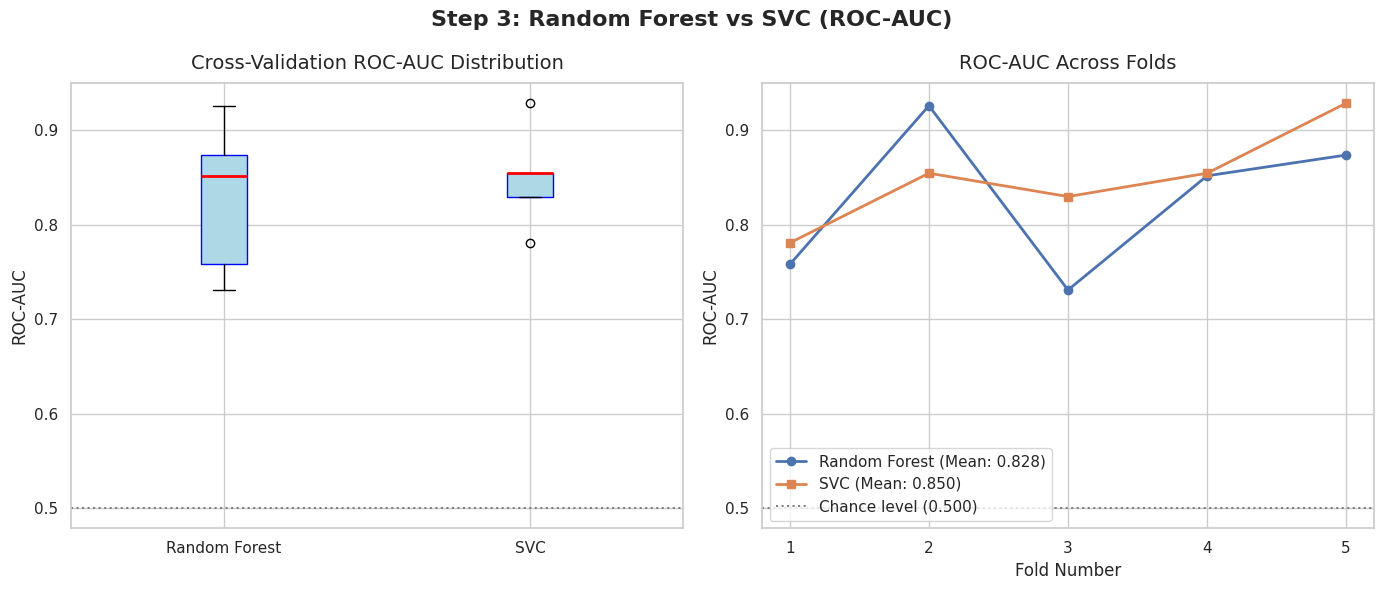

In [11]:
# 3a. ROC-AUC with 5-fold CV (same folds as in Step 2)
auc_scores = {name: cross_val_score(model, X, y, cv=cv, scoring='roc_auc') for name, model in models.items()}

print("=== 5-Fold ROC-AUC Cross-Validation Results ===\n")
for name, scores in auc_scores.items():
    report_cv(name, scores, 'ROC-AUC')

plot_cv_comparison(auc_scores, 'ROC-AUC', 'Step 3: Random Forest vs SVC (ROC-AUC)',
                   baseline=0.5, baseline_label='Chance level')

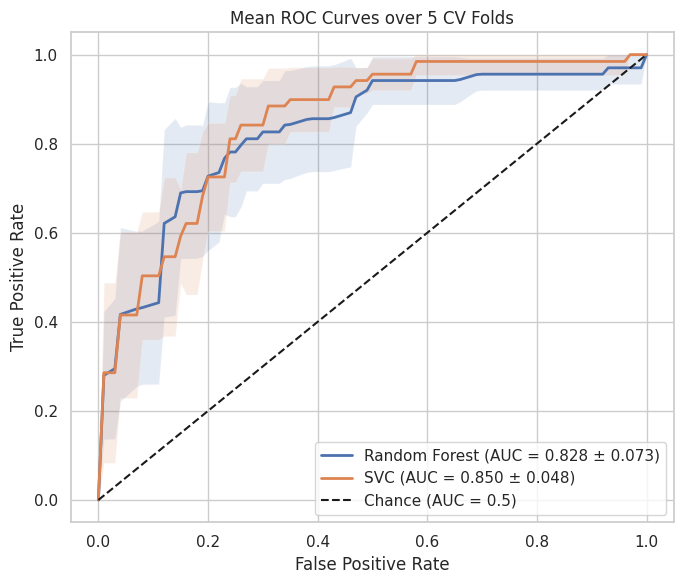

In [12]:
# 3b. Mean ROC curve across the CV folds (+/- 1 std)
def get_scores(fitted_model, X_eval):
    """Continuous score of the positive class: decision function if available, else predicted probability."""
    if hasattr(fitted_model, 'decision_function'):
        return fitted_model.decision_function(X_eval)
    return fitted_model.predict_proba(X_eval)[:, 1]


def cv_roc_curves(model, X, y, cv, grid=np.linspace(0, 1, 101)):
    tprs, aucs = [], []
    for train_idx, test_idx in cv.split(X, y):
        fitted = clone(model).fit(X.iloc[train_idx], y.iloc[train_idx])
        scores = get_scores(fitted, X.iloc[test_idx])
        fpr, tpr, _ = roc_curve(y.iloc[test_idx], scores)
        interp_tpr = np.interp(grid, fpr, tpr)
        interp_tpr[0] = 0.0
        tprs.append(interp_tpr)
        aucs.append(roc_auc_score(y.iloc[test_idx], scores))
    return grid, np.array(tprs), np.array(aucs)


fig, ax = plt.subplots(figsize=(7, 6))
for name, model in models.items():
    grid, tprs, aucs = cv_roc_curves(model, X, y, cv)
    mean_tpr, std_tpr = tprs.mean(axis=0), tprs.std(axis=0)
    ax.plot(grid, mean_tpr, linewidth=2, label=f'{name} (AUC = {aucs.mean():.3f} ± {aucs.std():.3f})')
    ax.fill_between(grid, np.clip(mean_tpr - std_tpr, 0, 1), np.clip(mean_tpr + std_tpr, 0, 1), alpha=0.15)
ax.plot([0, 1], [0, 1], 'k--', label='Chance (AUC = 0.5)')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('Mean ROC Curves over 5 CV Folds')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

Train: 160 samples | Test: 40 samples
Majority-class baseline accuracy on the test set: 0.65

=== Random Forest ===
Test accuracy: 0.75 | Test ROC-AUC: 0.84
              precision    recall  f1-score   support

   Sensitive       0.79      0.85      0.81        26
   Resistant       0.67      0.57      0.62        14

    accuracy                           0.75        40
   macro avg       0.73      0.71      0.72        40
weighted avg       0.74      0.75      0.75        40

=== SVC ===
Test accuracy: 0.75 | Test ROC-AUC: 0.87
              precision    recall  f1-score   support

   Sensitive       0.77      0.88      0.82        26
   Resistant       0.70      0.50      0.58        14

    accuracy                           0.75        40
   macro avg       0.73      0.69      0.70        40
weighted avg       0.74      0.75      0.74        40



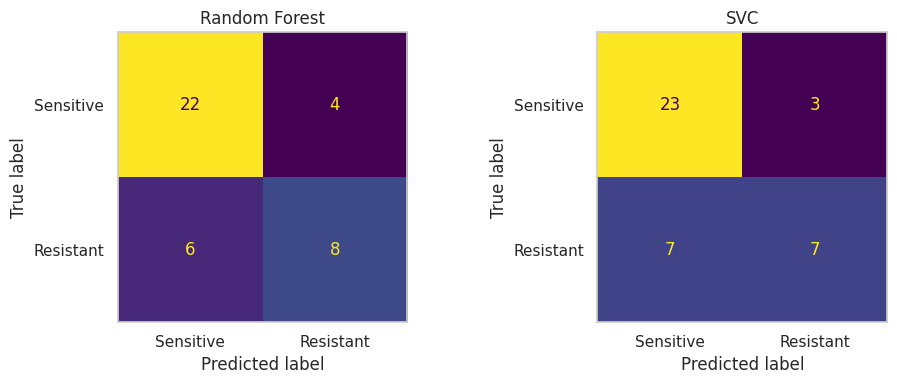

In [13]:
# 3c. Hold-out test: 80% train / 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print(f"Train: {len(X_train)} samples | Test: {len(X_test)} samples")
print(f"Majority-class baseline accuracy on the test set: {(y_test == y_train.mode()[0]).mean():.2f}\n")

fitted_models = {}
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, models.items()):
    fitted_models[name] = clone(model).fit(X_train, y_train)
    y_pred = fitted_models[name].predict(X_test)
    y_score = get_scores(fitted_models[name], X_test)

    print(f"=== {name} ===")
    print(f"Test accuracy: {accuracy_score(y_test, y_pred):.2f} | Test ROC-AUC: {roc_auc_score(y_test, y_score):.2f}")
    print(classification_report(y_test, y_pred, target_names=['Sensitive', 'Resistant']))

    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['Sensitive', 'Resistant'],
                                            ax=ax, colorbar=False)
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.show()

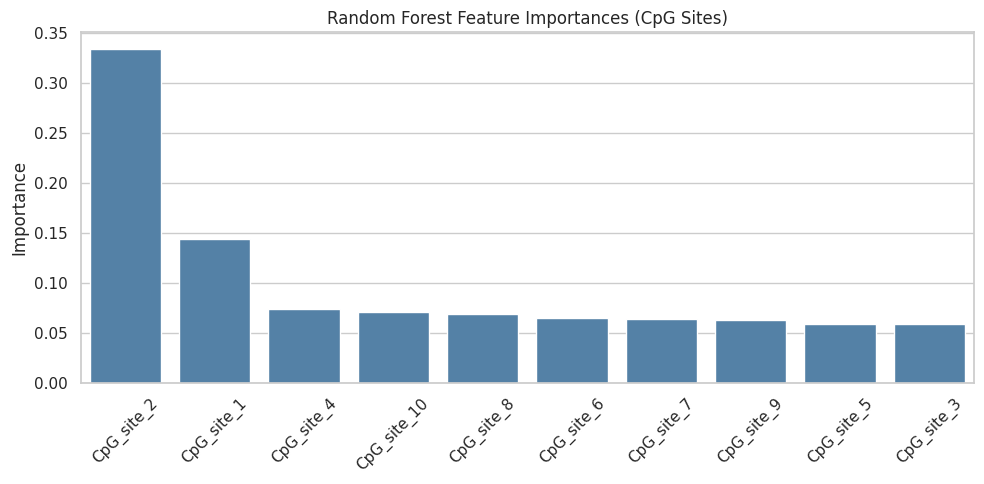

In [14]:
# Random Forest feature importances (from the hold-out fit; with only 160 training samples they are noisy)
rf_fitted = fitted_models['Random Forest'].named_steps['clf']
importances = pd.Series(rf_fitted.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=importances.index, y=importances.values, color='steelblue')
plt.title("Random Forest Feature Importances (CpG Sites)")
plt.ylabel("Importance")
plt.xlabel("")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Step 4: Imbalance Handling Techniques

The classes are mildly imbalanced (about 1.9 : 1). For both models we compare:
* **Baseline**: no correction
* **SMOTE**: synthetic minority-class samples
* **ROS**: random over-sampling of the minority class
* **Class weight**: cost-sensitive learning (`class_weight='balanced'`)

Resampling is placed *inside* the pipeline, so it is applied only to the training part of each fold. Over-sampling before the split would leak duplicated or synthetic samples into the validation folds and inflate the scores.

Besides ROC-AUC (which does not depend on the decision threshold), we report **balanced accuracy** and the **F1 score of the resistant (minority) class**, because these show how each technique affects the minority class.

In [15]:
scoring = {'roc_auc': 'roc_auc', 'balanced_accuracy': 'balanced_accuracy', 'f1': 'f1'}  # f1 = resistant class (label 1)

cv_results = {}
for model_name in models:
    for method in METHODS:
        cv_results[(model_name, method)] = cross_validate(
            build_pipeline(model_name, method), X, y, cv=cv, scoring=scoring)

summary_df = pd.DataFrame([
    {
        'Model': model_name,
        'Method': method,
        'ROC-AUC': res['test_roc_auc'].mean(),
        'ROC-AUC Std': res['test_roc_auc'].std(),
        'Balanced Acc.': res['test_balanced_accuracy'].mean(),
        'F1 (Resistant)': res['test_f1'].mean(),
    }
    for (model_name, method), res in cv_results.items()
]).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)

print("=== IMBALANCE HANDLING METHODS PERFORMANCE TABLE (5-fold CV) ===")
display(summary_df.round(4))

=== IMBALANCE HANDLING METHODS PERFORMANCE TABLE (5-fold CV) ===


,Model,Method,ROC-AUC,ROC-AUC Std,Balanced Acc.,F1 (Resistant)
0,SVC,SMOTE,0.8497,0.0494,0.7610,0.6853
1,SVC,Baseline,0.8495,0.0478,0.7046,0.5983
2,SVC,Class weight,0.8430,0.0467,0.7627,0.6882
3,Random Forest,SMOTE,0.8357,0.0830,0.7123,0.6262
4,SVC,ROS,0.8353,0.0507,0.7385,0.6577
5,Random Forest,Class weight,0.8311,0.0643,0.6939,0.5837
6,Random Forest,Baseline,0.8279,0.0729,0.7334,0.6379
7,Random Forest,ROS,0.8246,0.0763,0.7138,0.6223


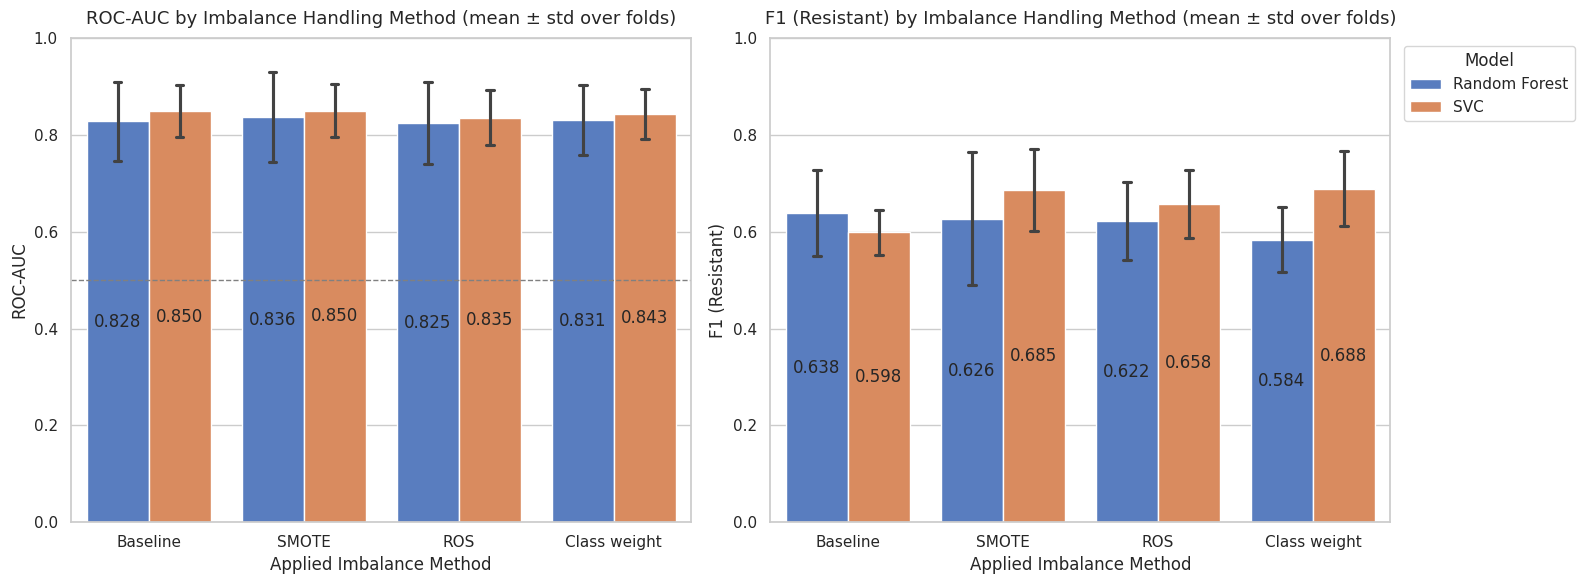

In [16]:
fold_df = pd.DataFrame([
    {'Model': model_name, 'Method': method, 'ROC-AUC': auc, 'F1 (Resistant)': f1}
    for (model_name, method), res in cv_results.items()
    for auc, f1 in zip(res['test_roc_auc'], res['test_f1'])
])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, metric in zip(axes, ['ROC-AUC', 'F1 (Resistant)']):
    sns.barplot(data=fold_df, x='Method', y=metric, hue='Model', order=METHODS,
                palette='muted', errorbar='sd', capsize=0.1, ax=ax)
    for container in ax.containers:
        ax.bar_label(container, fmt='%.3f', label_type='center')
    ax.set_title(f'{metric} by Imbalance Handling Method (mean ± std over folds)', fontsize=13, pad=10)
    ax.set_xlabel('Applied Imbalance Method', fontsize=12)
    ax.set_ylabel(metric, fontsize=12)
    ax.set_ylim(0, 1)
axes[0].axhline(0.5, color='gray', linestyle='--', linewidth=1)   # chance level for ROC-AUC
axes[0].get_legend().remove()
axes[1].legend(title='Model', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Summary of Project Workflow and Key Findings

This notebook builds and evaluates a machine-learning pipeline that predicts **chemotherapy resistance** from synthetic **DNA methylation** levels at 10 CpG sites.

### 1. Data exploration
* **Synthetic dataset:** 200 samples x 10 CpG sites (beta values between 0 and 1). The labels were generated from a *linear* (logistic) combination of `CpG_site_1` (higher value -> more resistant) and `CpG_site_2` (higher value -> more sensitive) plus noise.
* **Class imbalance:** 131 Sensitive vs. 69 Resistant samples (about 1.9 : 1). A model that always predicts "Sensitive" already reaches 0.655 accuracy (ROC-AUC = 0.5), so this is the baseline to beat.
* **Data quality:** no missing values; the CpG sites are almost uncorrelated (largest absolute correlation 0.16), so collinearity is not an issue.

### 2. Model comparison (stratified 5-fold CV, scaler inside the pipeline)

| Metric | Random Forest | SVC | Majority-class baseline |
|---|---|---|---|
| Accuracy (mean ± std) | 0.775 ± 0.035 | 0.755 ± 0.019 | 0.655 |
| ROC-AUC (mean ± std) | 0.828 ± 0.073 | 0.850 ± 0.048 | 0.500 |

* Both models are clearly better than the baseline (about 10 to 12 percentage points higher accuracy).
* Random Forest has the slightly higher accuracy, SVC the slightly higher ROC-AUC and a lower variance across folds. The differences (about 0.02) are smaller than the fold-to-fold standard deviation, so with only 200 samples neither model can be declared the winner.
* **Hold-out test (40 samples):** both models reach 0.75 accuracy (ROC-AUC 0.84 for RF, 0.87 for SVC). With the default threshold they find only about half of the resistant samples (recall 0.57 for RF, 0.50 for SVC). One test sample is worth 2.5 percentage points, so the cross-validation results are the more reliable estimate.
* **Feature importance:** `CpG_site_2` (about 0.33) and `CpG_site_1` (about 0.14) clearly dominate, which matches how the data were generated. The remaining sites are at noise level (about 0.06 to 0.07).

### 3. Imbalance handling (Step 4)
* The ROC-AUC of all eight configurations (2 models x 4 methods) stays within a narrow band (roughly 0.82 to 0.85), while the fold-to-fold standard deviation is 0.05 to 0.08. No technique therefore changes the *ranking* quality of the models in a meaningful way. This is expected: the imbalance is mild and ROC-AUC does not depend on the decision threshold.
* The techniques mainly move the decision threshold towards the minority class. Compare the **Balanced Acc.** and **F1 (Resistant)** columns of the Step 4 table with the *Baseline* rows to see this effect; class weighting raised both metrics for both models in our runs.

### Key takeaways
1. Methylation at `CpG_site_1` and `CpG_site_2` carries almost all of the predictive signal; both models recover it with ROC-AUC of about 0.83 to 0.85.
2. SVC and Random Forest perform comparably. SVC is slightly more stable, so it is a reasonable default.
3. If missing resistant samples is costly, use class weights or resampling to raise recall of the resistant class. If only the ranking matters (ROC-AUC), no correction is needed.
4. **Limitations:** synthetic data, only 200 samples, no hyperparameter tuning, and all comparisons share the same CV folds. For firm conclusions, repeat the cross-validation with several random seeds.